# IS4487 Week 4 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_04_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Case: AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

For this assignment, the variable `answered` is your target.  

### AdviseInvest Data Dictionary

| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: female; 1: male |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |


### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import matplotlib as plot
import sklearn as sk

## Step 1: Initial Data Understanding

### Do the following:
 1. Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 2. Show the datatypes
 3. Describe the dataset

 Think about if there are any outliers, missing values, or duplicates.  We will cover those topics more next week.  

In [12]:
df = pd.read_csv("adviseinvest_historical_data.csv")
df.head()

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


In [13]:
df.dtypes

,0
customer_id,int64
answered,int64
income,int64
female,object
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,float64


In [15]:
display(df.describe())

,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


Question 1.4: Do you see any variables that have potential outliers?  What indicators do you see the the values are out of the normal range?  (don't worry about using a scientific approach for outliers at this stage; just use your best judgment)

### ✍️ Your Response: 🔧
1.4. One of the potential outliers I see is the -65600 income compared to the rest.There are two others in the describe data set, which are the count row and the max age. The indicator for the age is that it is highly unlikely for someone to live to be 132 years old and the other two are you are not likely to have a negative income as well as the count is most likely a typo since all the numeric values are roughly the same.

# Step 2: Begin to Explore the Data

We will learn more about Exploratory Data Analysis (EDA) in Week 5. The following steps are to help you connect the data visualization steps that we practiced last week with the process of data understanding - learning more about the dataset and finding the data quality issues that need to be addressed.   These are the first steps in EDA.

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted

/tmp/ipykernel_4645/3380520709.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='mobile', y='answered', ci=None, palette='Blues_d')
/tmp/ipykernel_4645/3380520709.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='mobile', y='answered', ci=None, palette='Blues_d')


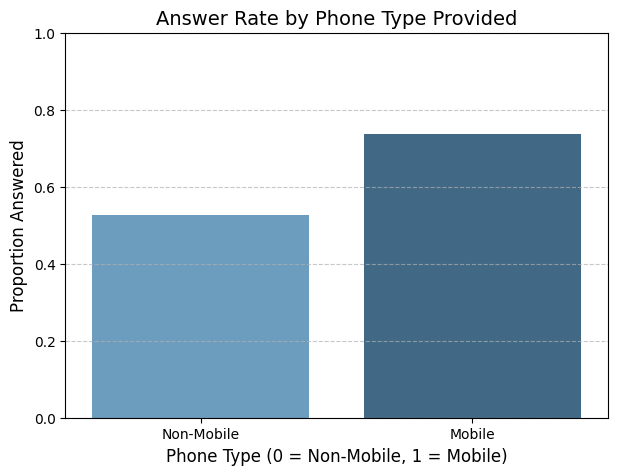

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='mobile', y='answered', ci=None, palette='Blues_d')
plt.title('Answer Rate by Phone Type Provided', fontsize=14)
plt.xlabel('Phone Type (0 = Non-Mobile, 1 = Mobile)', fontsize=12)
plt.ylabel('Proportion Answered', fontsize=12)
plt.xticks([0, 1], ['Non-Mobile', 'Mobile'])
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_4645/3125388128.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='answered', y='income', palette='Set2')


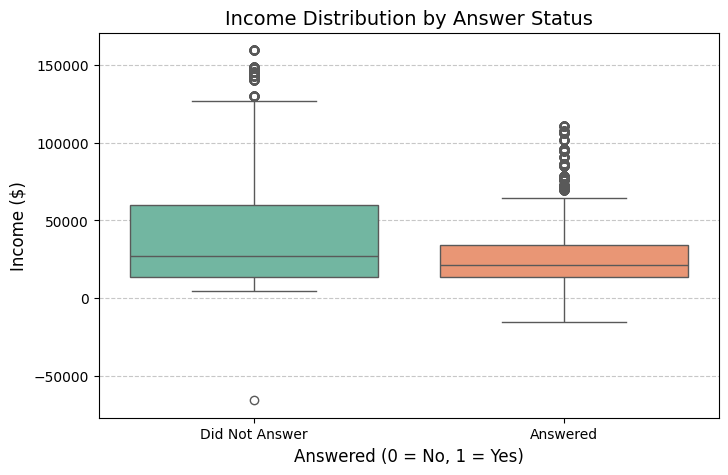

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='answered', y='income', palette='Set2')
plt.title('Income Distribution by Answer Status', fontsize=14)
plt.xlabel('Answered (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Income ($)', fontsize=12)
plt.xticks([0, 1], ['Did Not Answer', 'Answered'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

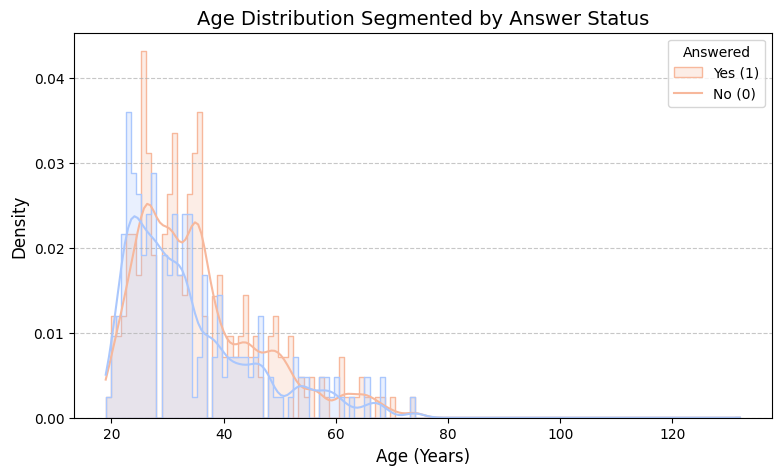

In [18]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='age', hue='answered', kde=True, element='step', palette='coolwarm', stat='density')
plt.title('Age Distribution Segmented by Answer Status', fontsize=14)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Answered', labels=['Yes (1)', 'No (0)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

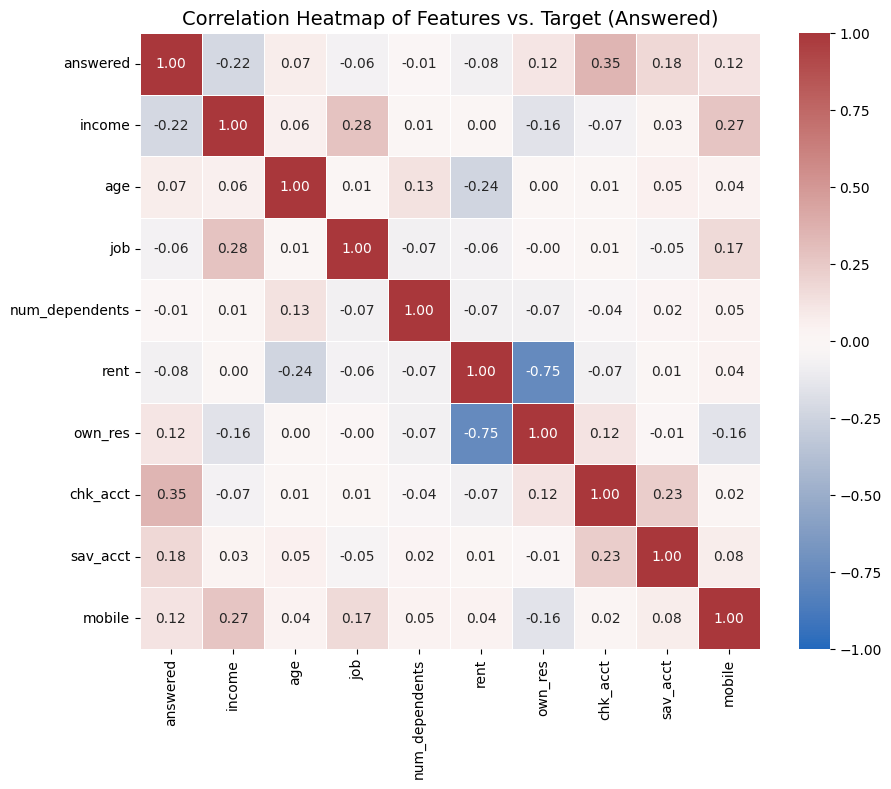

In [19]:
plt.figure(figsize=(10, 8))
corr_vars = ['answered', 'income', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'chk_acct', 'sav_acct', 'mobile']
corr = df[corr_vars].corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Features vs. Target (Answered)', fontsize=14)
plt.show()

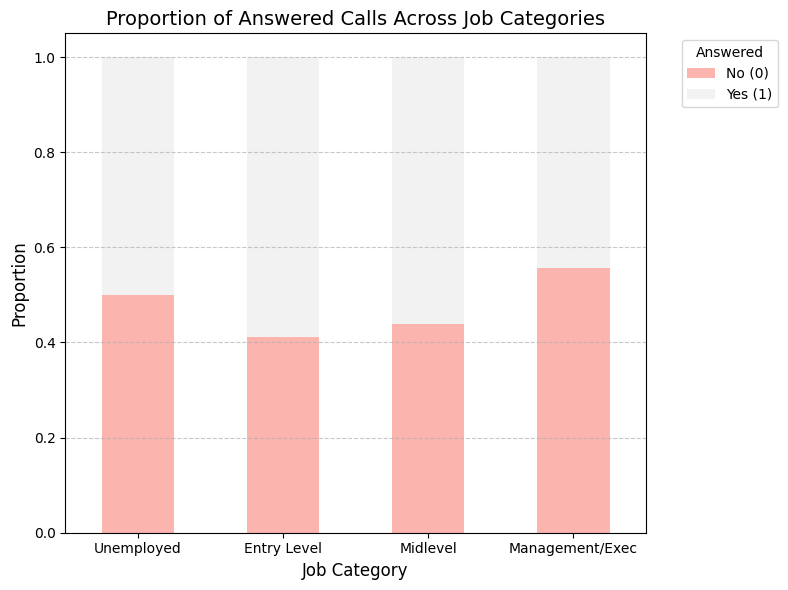

In [20]:
job_counts = pd.crosstab(df['job'], df['answered'], normalize='index')

ax = job_counts.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='Pastel1')
plt.title('Proportion of Answered Calls Across Job Categories', fontsize=14)
plt.xlabel('Job Category', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks([0, 1, 2, 3], ['Unemployed', 'Entry Level', 'Midlevel', 'Management/Exec'], rotation=0)
plt.legend(title='Answered', labels=['No (0)', 'Yes (1)'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Step 3: Summarize Your Findings
- Question 3.1: Which variables are NOT useful or applicable to the business need?  (you should reference the target variable and list any variables that are not correlated with the target)

- Question 3.2: Which variables are MOST useful or applicable to the business need, based on the output of your charts?   

- Question 3.3: List at least three ways that the dataset could be improved.  What data quality issues or data types should be fixed?



### ✍️ Your Response: 🔧
3.1 Customer_id: This is just an ID number for each customer. It doesn't tell us anything about their behavior, so it's useless for predicting who will answer.
Product: This shows what plan a customer bought after they already answered the call. Since it only exists after the fact, it can't help us predict answer rates ahead of time.
Female and num_dependents: Gender and number of dependents barely move the needle. Both have correlations close to 0.00 with answered, meaning they have almost no relationship to whether someone picks up.

3.2 Mobile: Big difference here. Customers who gave a mobile number answer way more often than those who gave a landline/non-mobile number.

chk_acct and sav_acct: How much money someone keeps in checking/savings is one of the strongest predictors. Customers with higher balances answer more often.

income: There's a real pattern, but it runs the opposite way you'd expect: lower-income customers actually answer more often than higher-income ones.

age: There's a mild trend where older customers answer slightly more often than younger ones, though it's a weaker effect than the account-balance variables.

3.3 Fix impossible values
income: some values are negative (as low as -$65,600) — income can't be negative, so these are errors.

age: one customer is listed as 132 years old which is clearly a mistake.
num_accts: one customer has 3,345 accounts which is way outside normal range, likely a typo.

Fix messy data types
female: should just be 0 or 1, but there's also a stray "M" in there. Needs to be cleaned up into a consistent 0/1 format.
new_car: stored with decimals (0.0/1.0) instead of clean whole numbers because of missing values — should be fixed to a clean yes/no format once the missing values are handled.

Handle missing data
new_car is missing for 2 customers. Instead of just leaving it blank, fill it in with a reasonable guess (like the most common value) or add a separate flag marking that it was missing.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas

In [ ]:
!jupyter nbconvert --to html "assignment_04_data_understanding.ipynb"